In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as pt
import seaborn as sns
from sklearn. metrics import mean_absolute_error, mean_squared_error,r2_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
from sklearn.metrics import accuracy_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt

In [ ]:
from google.colab import files
uploaded=files.upload()

Saving titanic.csv to titanic.csv


In [ ]:
df=pd.read_csv("titanic.csv")
print(df)

     PassengerId  Pclass                                          Name  \
0            892       3                              Kelly, Mr. James   
1            893       3              Wilkes, Mrs. James (Ellen Needs)   
2            894       2                     Myles, Mr. Thomas Francis   
3            895       3                              Wirz, Mr. Albert   
4            896       3  Hirvonen, Mrs. Alexander (Helga E Lindqvist)   
..           ...     ...                                           ...   
413         1305       3                            Spector, Mr. Woolf   
414         1306       1                  Oliva y Ocana, Dona. Fermina   
415         1307       3                  Saether, Mr. Simon Sivertsen   
416         1308       3                           Ware, Mr. Frederick   
417         1309       3                      Peter, Master. Michael J   

        Sex   Age  SibSp  Parch              Ticket      Fare Cabin Embarked  \
0      male  34.5      0      0

In [ ]:
print(df.shape)

(418, 12)


In [ ]:
print(df.columns)

Index(['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Cabin', 'Embarked', 'Survived'],
      dtype='object')


In [ ]:
print(df.dtypes)

PassengerId      int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
Survived         int64
dtype: object


In [ ]:
print(df.isnull().sum())

PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
Survived         0
dtype: int64


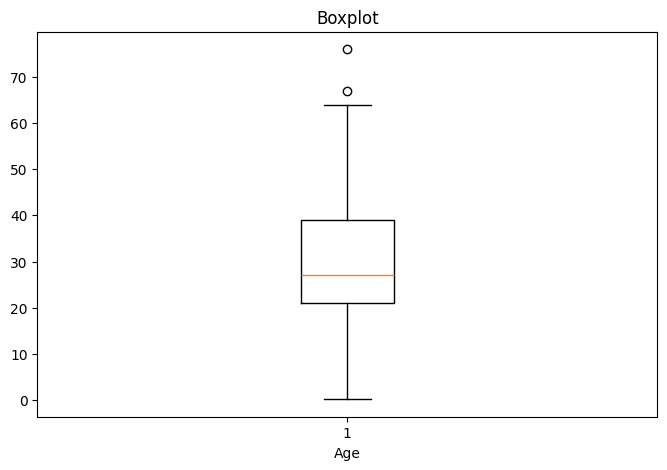

In [ ]:
pt.figure(figsize=(8, 5))
pt.boxplot(df["Age"].dropna())
pt.title("Boxplot")
pt.xlabel("Age")
pt.show()

In [ ]:
def RemoveOutlier(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df_clean = df[
        (df[column] >= lower_bound) &
        (df[column] <= upper_bound)
    ]
    return df_clean

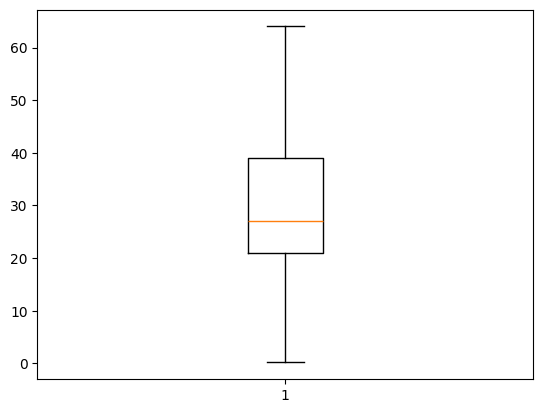

In [ ]:
df=RemoveOutlier(df, "Age")
pt.boxplot(df["Age"])
pt.show()

In [ ]:
print(df.shape)

(330, 12)


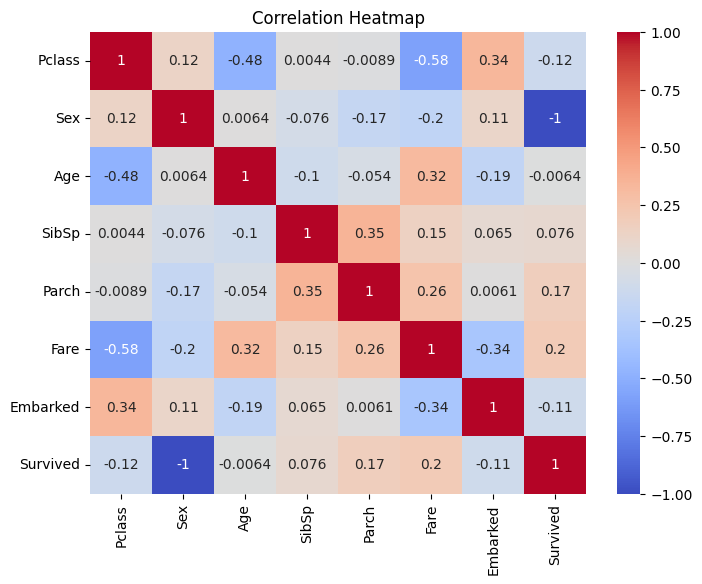

In [ ]:
pt.figure(figsize=(8,6))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)
pt.title("Correlation Heatmap")
pt.show()

In [ ]:
# Fill missing numerical values
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Fare"] = df["Fare"].fillna(df["Fare"].median())

# Fill missing categorical value
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

print(df.isnull().sum())

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
Survived    0
dtype: int64


In [ ]:
le_sex = LabelEncoder()
le_embarked = LabelEncoder()

df["Sex"] = le_sex.fit_transform(df["Sex"])
df["Embarked"] = le_embarked.fit_transform(df["Embarked"])


In [ ]:
X = df.drop("Survived", axis=1)
y = df["Survived"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (330, 7)
y shape: (330,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (264, 7)
Testing data: (66, 7)


In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
# 5. Build ANN model

model = Sequential()

model.add(Dense(16, input_dim=8, activation='relu'))
# Hidden Layer 1

model.add(Dense(8, activation='relu'))
# Hidden Layer 2

model.add(Dense(1, activation='sigmoid'))
# Output Layer (binary)

In [ ]:
model = Sequential()
model.add(Dense(16, input_dim=2, activation='relu'))
# Hidden Layer 1
model.add(Dense(8, activation='relu'))
 # Hidden Layer 2
model.add(Dense(1, activation='sigmoid'))
# Output Layer (binary)

In [ ]:
model = Sequential()
model.add(Dense(16, input_dim=7, activation='relu'))
model.add(Dense(8, activation='relu'))
model.add(Dense(1, activation='sigmoid'))


model.compile(
    loss='binary_crossentropy',
    optimizer=Adam(learning_rate=0.001),
    metrics=['accuracy']
)

model.fit(X_train, y_train, epochs=150, batch_size=16, verbose=0)


loss, accuracy = model.evaluate(X_test, y_test)

print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.2f}")
print(f"Test Accuracy: {accuracy * 100:.2f}%")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 1.0000 - loss: 2.0917e-04 
Test Loss: 0.0002
Test Accuracy: 1.00
Test Accuracy: 100.00%


In [ ]:
y_pred = model.predict(X_test)

y_pred_classes = (y_pred > 0.5).astype("int32")

print("Predicted values:")
print(y_pred_classes[:20])

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
Predicted values:
[[1]
 [0]
 [1]
 [0]
 [0]
 [0]
 [1]
 [0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [1]
 [0]
 [1]
 [1]
 [0]
 [1]
 [0]]


In [ ]:
accuracy = accuracy_score(y_test, y_pred_classes)

print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

Accuracy: 1.0
Accuracy (%): 100.0


In [ ]:
print(classification_report(y_test, y_pred_classes))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        41
           1       1.00      1.00      1.00        25

    accuracy                           1.00        66
   macro avg       1.00      1.00      1.00        66
weighted avg       1.00      1.00      1.00        66



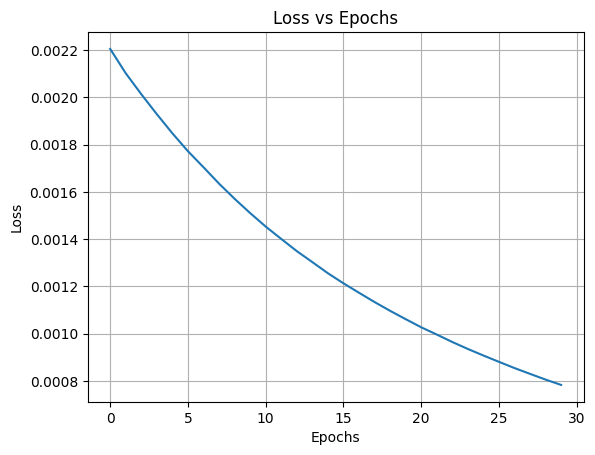

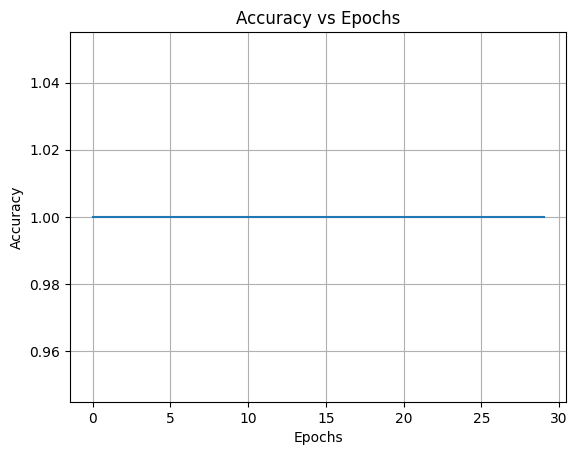

In [ ]:
# Plot Loss vs Epochs
# -----------------------------

plt.plot(history.history['loss'])

plt.title('Loss vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True)
plt.show()


# -----------------------------
# Plot Accuracy vs Epochs
# -----------------------------

plt.plot(history.history['accuracy'])

plt.title('Accuracy vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.grid(True)
plt.show()

Confusion Matrix:
[[41  0]
 [ 0 25]]


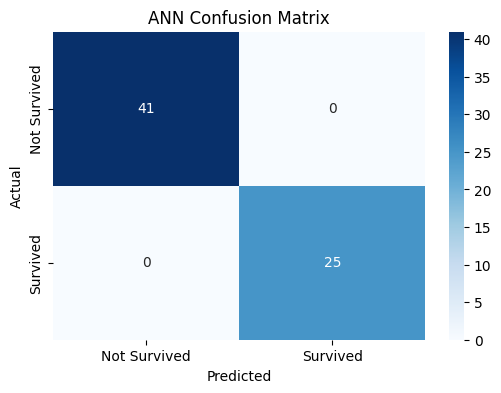

In [ ]:
cm = confusion_matrix(y_test, y_pred_classes)

print("Confusion Matrix:")
print(cm)

# Plot
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Survived", "Survived"],
    yticklabels=["Not Survived", "Survived"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ANN Confusion Matrix")

plt.show()